# FMATCH 4/10 — Ancillary sources: the box query, time matching and coverage

**Topic**: the layer between the readers (notebooks 2 and 3) and the PSF weighting
(notebook 5). It answers one question per footprint and per source: *which native samples
of this source belong to this footprint?* — those inside its bounding box, observed at the
right time. It never averages, bins or caches anything: each reader holds its source once
(a static reader its whole indexed body of data, a stepped reader the one hourly step
nearest the current footprint, a pass reader the hourly granules within `MAX_TIME_OFFSET`
of the current footprint), and every query is answered from that.

1. **`build_sources`** instantiates the readers active for an operational mode and
   returns them keyed by registry key; a footprint's samples of a source come from that
   reader's `samples_in(bbox, time)`. A static reader holds its
   whole source; a stepped reader one hourly step; a pass reader only the hourly granules
   within `MAX_TIME_OFFSET` of the current footprint time.
2. **The box query**: a grid is sliced on its axes; a point cloud is sorted once, at load,
   into 1° bins and only the bins the box overlaps are touched. A box that crosses the
   antimeridian is split into its two halves and both are served.
3. **Time matching** (`TimeMatch`): `DAILY` sources ignore time; `NEAREST_STEP` sources
   serve the hourly step nearest the footprint time; `NEAREST_PASS` sources serve the
   pass nearest the footprint time, whole, and nothing beyond `MAX_TIME_OFFSET`.
4. **Coverage** is measured by the weigher against the PSF contour, so a swath gap or a
   source outside its time window reads as missing — the quantity the CERES 75%/95%
   rule needs.


In [1]:
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
import libera_utils.footprint_matching.readers  # noqa: F401  (import triggers registration)
from libera_utils.footprint_matching import geometry
from libera_utils.footprint_matching.readers.base import split_dateline
from libera_utils.footprint_matching.readers.registry import ReaderRegistry
from libera_utils.footprint_matching.types import BoundingBox, OperationalMode
from libera_utils.footprint_matching.weighting import AngularPSFWeigher
from tests.plugins.footprint_matching_fixtures import (
    ERA5_FIXTURE_TIME,
    SWATH_FIXTURE_TIME,
    make_cldpix_fixture,
    make_era5_surface_netcdf_fixture,
)

workdir = Path(tempfile.mkdtemp(prefix="fmatch_nb04_"))
# Stand-in for L1B Radius_of_Satellite_from_Center_of_Earth (an ~835 km orbit), km.
SATELLITE_RADIUS_KM = 7213.0

## 1. The active readers of a mode

`build_sources(mode, source_file_paths)` returns a dict with one reader per source the
mode's product uses, over the granules staged for it; a reader missing from the map, or a
key the mode does not use, is an error, not a silent gap. It needs a granule for every one
of them, so the demo builds the same kind of dict directly over two of IMAGER's readers: a
global ERA5 file with three hourly steps (`NEAREST_STEP`), and a CLDPIX swath
(`NEAREST_PASS`).


In [3]:
# ERA5: a global 0.5 degree grid with three hourly steps; u10 holds the step index so a served
# value tells which step it came from.
steps = ERA5_FIXTURE_TIME + np.arange(3) * np.timedelta64(1, "h")
era5_path = make_era5_surface_netcdf_fixture(
    workdir,
    lat_min=-90.0,
    lat_max=90.0,
    lon_min=-180.0,
    lon_max=179.5,
    n_lat=361,
    n_lon=720,
    times=steps,
    u10_per_step=np.array([0.0, 1.0, 2.0]),
)
# CLDPIX: a pixel ribbon crossing lat [2, 4], lon [12, 14] at the swath fixture time.
nscan, npix = 60, 12
scan = np.linspace(1.0, 5.0, nscan)
across = np.linspace(-1.0, 1.0, npix)
sw_lat = (scan[:, None] + 0.15 * across[None, :]).astype(np.float32)
sw_lon = (13.0 + 1.6 * across[None, :] + 0.2 * (scan[:, None] - 3.0)).astype(np.float32)
cldpix_path = make_cldpix_fixture(workdir, lats=sw_lat, lons_0360=sw_lon)

readers = {
    "era5_surface": ReaderRegistry.get("era5_surface")([era5_path]),
    "cldpix": ReaderRegistry.get("cldpix")([cldpix_path]),
}
print("IMAGER uses:", sorted(ReaderRegistry.get_readers_for_mode(OperationalMode.IMAGER)))
print("demo readers:", sorted(readers))
for key, reader in sorted(readers.items()):
    print(
        f"  {key:7s} TIME_MATCH={reader.TIME_MATCH.value:13s} MAX_TIME_OFFSET={reader.MAX_TIME_OFFSET}  PASS_WINDOW={reader.PASS_WINDOW}"
    )

IMAGER uses: ['cldpix', 'era5_pressure', 'era5_surface', 'flashflux', 'igbp', 'nise', 'viirs_aod', 'viirs_brdf', 'viirs_cldprop_d3']
demo readers: ['cldpix', 'era5_surface']
  cldpix  TIME_MATCH=nearest_pass  MAX_TIME_OFFSET=3 hours  PASS_WINDOW=15 minutes
  era5_surface TIME_MATCH=nearest_step  MAX_TIME_OFFSET=1 hours  PASS_WINDOW=None


## 2. The box query

A footprint's ray-traced `BoundingBox` (notebook 1) goes in; a `SampleSet` of the source's
native samples inside it comes out, with one value row per variable. For the grid source
that is a slice on the latitude and longitude axes; for the point source it is a lookup in
the 1° bins followed by the exact box mask.


In [4]:
bbox = geometry.compute_footprint_bounding_box(
    boresight_lat_deg=3.0,
    boresight_lon_deg=13.0,
    subsatellite_lat_deg=3.4,
    subsatellite_lon_deg=13.0,
    satellite_radius_km=SATELLITE_RADIUS_KM,
)
print("footprint box:", bbox)
era5_samples = readers["era5_surface"].samples_in(bbox, ERA5_FIXTURE_TIME)
cld_samples = readers["cldpix"].samples_in(bbox, SWATH_FIXTURE_TIME)
print(
    f"era5   : {era5_samples.n_samples:4d} grid points, values {era5_samples.values.shape}, times={era5_samples.times}"
)
print(
    f"cldpix : {cld_samples.n_samples:4d} pixels,      values {cld_samples.values.shape}, times {cld_samples.times.min()} .. {cld_samples.times.max()}"
)

footprint box: BoundingBox(lat=[2.8135763019763544, 3.1858021739588867], lon=[12.825975380670407, 13.174024619329595], wraps_dateline=False, is_polar=False, truncated=False)
era5   :    1 grid points, values (7, 1), times=None
cldpix :   20 pixels,      values (9, 20), times 2026-01-01T12:00:00.000000000 .. 2026-01-01T12:00:00.000000000


## 3. Antimeridian-crossing boxes are split, not stretched

A box that crosses ±180° is given in the [0, 360) form with `lon_max > 180`. The base class
splits it into its west and east halves, queries each, and concatenates the samples, so
the footprint sees one contiguous set of samples on both sides of the line.


In [5]:
dateline_box = BoundingBox(0.0, 1.0, 179.0, 181.0, wraps_dateline=True)
print("halves:", split_dateline(dateline_box))
served = readers["era5_surface"].samples_in(dateline_box, ERA5_FIXTURE_TIME)
print(f"{served.n_samples} ERA5 grid points served; longitudes {sorted(set(served.lons.tolist()))}")

halves: [BoundingBox(lat=[0.0, 1.0], lon=[179.0, 180.0], wraps_dateline=False, is_polar=False, truncated=False), BoundingBox(lat=[0.0, 1.0], lon=[-180.0, -179.0], wraps_dateline=False, is_polar=False, truncated=False)]
15 ERA5 grid points served; longitudes [-180.0, -179.5, -179.0, 179.0, 179.5]


## 4. Time matching

### 4a. `NEAREST_STEP`: the hourly step nearest the footprint time

ERA5 serves one step at a time and reloads only when the nearest step changes, which
happens about once an hour because footprints arrive in time order. Beyond
`MAX_TIME_OFFSET` (1 h from every staged step) nothing is served.


In [6]:
print(f"{'footprint time':>28s}  {'served u10':>10s}  (0, 1, 2 = step index)")
for minutes in (5, 25, 35, 85, 125, 300):
    when = ERA5_FIXTURE_TIME + np.timedelta64(minutes, "m")
    s = readers["era5_surface"].samples_in(bbox, when)
    value = "no samples" if s.n_samples == 0 else f"{float(s.values[0, 0]):.0f}"
    print(f"{str(when)[:16]:>28s}  {value:>10s}")

              footprint time  served u10  (0, 1, 2 = step index)
            2026-01-01T00:05           0
            2026-01-01T00:25           0
            2026-01-01T00:35           1
            2026-01-01T01:25           1
            2026-01-01T02:05           2
            2026-01-01T05:00  no samples


### 4b. `NEAREST_PASS`: one pass, whole

A day of swath data sees the same ground on more than one pass. We stage a second CLDPIX
granule observing the same pixels twelve hours later. For any footprint time, the reader
keeps the pixels within `PASS_WINDOW` (15 min) of the smallest time offset — the nearest
pass, all of it, and never the other — and nothing when that offset exceeds
`MAX_TIME_OFFSET` (3 h).


In [7]:
late_time = SWATH_FIXTURE_TIME + np.timedelta64(12, "h")
late_path = make_cldpix_fixture(
    workdir,
    lats=sw_lat,
    lons_0360=sw_lon,
    times=np.full(nscan, late_time, dtype="datetime64[ns]"),
    filename="cldpix_late.nc",
)
two_passes = ReaderRegistry.get("cldpix")([cldpix_path, late_path])

print(f"{'footprint time':>22s}  pixels  pass")
for label, when in [
    ("pass 1 + 20 min", SWATH_FIXTURE_TIME + np.timedelta64(20, "m")),
    ("pass 2 - 30 min", late_time - np.timedelta64(30, "m")),
    ("6 h from either", SWATH_FIXTURE_TIME + np.timedelta64(6, "h")),
]:
    s = two_passes.samples_in(bbox, when)
    which = "-" if s.n_samples == 0 else ("1" if s.times[0] == SWATH_FIXTURE_TIME else "2")
    print(f"{label:>22s}  {s.n_samples:6d}  {which}")

        footprint time  pixels  pass
       pass 1 + 20 min      20  1
       pass 2 - 30 min      20  2
       6 h from either       0  -


## 5. Coverage comes from the weigher, against the PSF contour

The samples served say nothing about what is *missing*: a swath gap has no samples. So
the weigher lays a reference grid over the PSF contour and counts the share of the PSF's
energy that lies inside the native cell (`RESOLUTION_KM`) of at least one finite sample.
Below, the same footprint against the CLDPIX ribbon in three cases: on the pass (full
coverage), at the edge of the ribbon (partial), beyond the time window (none).


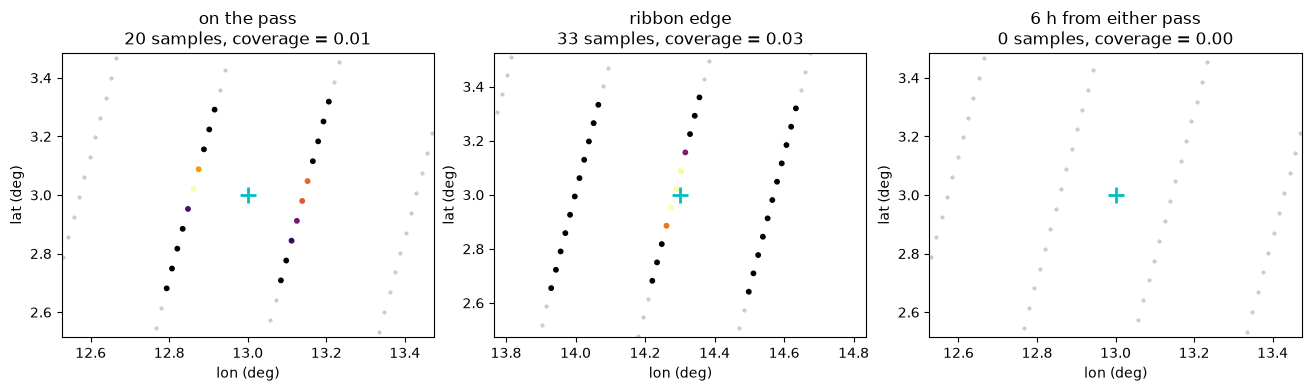

In [8]:
weigher = AngularPSFWeigher()
viewing = dict(subsatellite_lat_deg=3.4, subsatellite_lon_deg=13.0, satellite_radius_km=SATELLITE_RADIUS_KM)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
cases = [
    ("on the pass", 3.0, 13.0, SWATH_FIXTURE_TIME + np.timedelta64(5, "m")),
    ("ribbon edge", 3.0, 14.3, SWATH_FIXTURE_TIME + np.timedelta64(5, "m")),
    ("6 h from either pass", 3.0, 13.0, SWATH_FIXTURE_TIME + np.timedelta64(6, "h")),
]
for ax, (label, lat, lon, when) in zip(axes, cases, strict=True):
    fp_box = geometry.compute_footprint_bounding_box(boresight_lat_deg=lat, boresight_lon_deg=lon, **viewing)
    s = two_passes.samples_in(fp_box, when)
    wf = weigher.weight_field(
        s,
        lat,
        lon,
        **viewing,
        viewing_zenith_deg=20.0,
        cone_angle_rate=-1.0,
        sample_resolution_km=two_passes.RESOLUTION_KM,
    )
    ax.scatter(sw_lon, sw_lat, s=4, color="0.8", label="ribbon pixels")
    if s.n_samples:
        ax.scatter(s.lons, s.lats, c=wf.weights, s=10, cmap="inferno", label="served, PSF weight")
    ax.plot(lon, lat, "c+", ms=12, mew=2)
    ax.set_xlim(fp_box.lon_min - 0.3, fp_box.lon_max + 0.3)
    ax.set_ylim(fp_box.lat_min - 0.3, fp_box.lat_max + 0.3)
    ax.set_title(f"{label}\n{s.n_samples} samples, coverage = {wf.coverage:.2f}")
    ax.set_xlabel("lon (deg)")
    ax.set_ylabel("lat (deg)")
plt.show()

## Where this goes next in the stack

- **Notebook 5** weights the served samples with the PSF and aggregates them to one value
  per product variable.
- The orchestrator (FMATCH 7) calls each active reader's `samples_in` for each footprint,
  hands the samples to the weigher, and takes the minimum coverage across sources as the
  footprint's `psf_coverage_fraction`.
